## Create a Granta MI Session

Import the GRANTA_MIScriptingToolkit package, and create a connection to a Granta MI server.

In [1]:
import datetime
import GRANTA_MIScriptingToolkit as gdl
from GRANTA_MIScriptingToolkit import granta as mpy
import numpy as np

usernameVal = 'STK_user'
passwordVal = 'P455w07d!'

session = mpy.connect('https://nanomecommons.grantami.com/mi_servicelayer', user_name=usernameVal, password=passwordVal)

## Get tabular data attribute information

In [2]:
dbKey = "MI_Blank_v2021"
tableName = "Indentation test data"
recordName = "Ni-SiC"

db = session.get_db(db_key=dbKey)
table = db.get_table(tableName)
Indrecord = table.search_for_records_by_name(recordName)[0]
samplesVal = Indrecord.attributes["Mechanical properties matrix"].value[:]
samplesUnit = Indrecord.attributes["Mechanical properties matrix"]
samplesVal

[[[130941.304], [83234.0], None, [268.2], [6.58], None, ''],
 [[130939.304], [83234.0], None, [177.3], [4.76], None, ''],
 [[130937.304], [83234.0], None, [233.3], [4.42], None, ''],
 [[130935.304], [83234.0], None, [4.0], [0.15], None, ''],
 [[130933.304], [83234.0], None, [223.6], [5.0], None, ''],
 [[130931.304], [83234.0], None, [235.6], [4.98], None, ''],
 [[130929.304], [83234.0], None, [216.6], [3.64], None, ''],
 [[130927.304], [83234.0], None, [216.3], [3.93], None, ''],
 [[130925.304], [83234.0], None, [229.3], [5.24], None, ''],
 [[130923.304], [83234.0], None, [235.8], [5.18], None, ''],
 [[130921.304], [83234.0], None, [225.7], [4.77], None, ''],
 [[130919.304], [83234.0], None, [276.5], [23.97], None, ''],
 [[130917.304], [83234.0], None, [287.2], [8.41], None, ''],
 [[130915.304], [83234.0], None, [259.6], [6.78], None, ''],
 [[130913.304], [83234.0], None, [260.9], [6.69], None, ''],
 [[130911.304], [83234.0], None, [234.9], [5.18], None, ''],
 [[130909.304], [83234.0],

# 1st option to load and to plot tabular data

In [3]:
columns=['X position (µm)', 'Y position (µm)', 'Z position (µm)', 'Elastic modulus (GPa)', 'Hardness (GPa)', 'Creep (nm)']

import pandas as pd
df = pd.DataFrame(samplesVal)
df = df.iloc[:, :-1]
for i in range(0, len(df.columns)):
    df[i] = df[i].str[0]
    df = df.rename(columns={i: columns[i]})
    
df = df.fillna(0)
display(df)

,X position (µm),Y position (µm),Z position (µm),Elastic modulus (GPa),Hardness (GPa),Creep (nm)
0,130941.304,83234.0,0,268.2,6.58,0
1,130939.304,83234.0,0,177.3,4.76,0
2,130937.304,83234.0,0,233.3,4.42,0
3,130935.304,83234.0,0,4.0,0.15,0
4,130933.304,83234.0,0,223.6,5.00,0
...,...,...,...,...,...,...
620,130901.304,83186.0,0,225.2,3.80,0
621,130899.304,83186.0,0,266.2,6.79,0
622,130897.304,83186.0,0,136.9,2.26,0
623,130895.304,83186.0,0,211.0,9.31,0


In [4]:
print(df.loc[[608]])

     X position (µm)  Y position (µm)  Z position (µm)  Elastic modulus (GPa)  \
608       130925.304          83186.0                0                    0.0   

     Hardness (GPa)  Creep (nm)  
608             0.0           0  


<Axes: xlabel='Hardness (GPa)', ylabel='Elastic modulus (GPa)'>

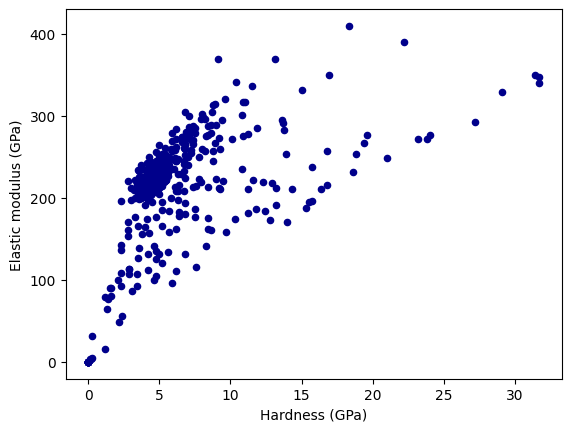

In [5]:
import matplotlib.pyplot as plt
df=df.round(1)
df.plot.scatter(x='Hardness (GPa)', y='Elastic modulus (GPa)', c='DarkBlue')

# 2nd option to load and to plot tabular data

<Axes: xlabel='Hardness (GPa)', ylabel='Elastic modulus (GPa)'>

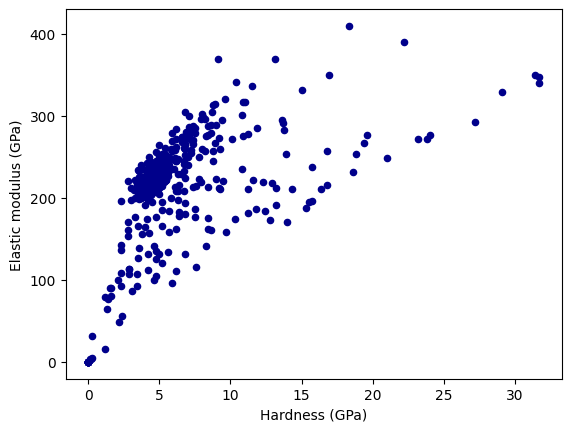

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

cleanData = []
for row in samplesVal:
    cleanRow = []
    for x in row:
        try:
            cleanRow.append(x[0])
        except:
            cleanRow.append(0)
    cleanData.append(cleanRow)
    

dfMat = pd.DataFrame(cleanData)
del dfMat[dfMat. columns[-1]]
dfMat.rename(columns = {0:'X coordinate (µm)', 
                        1:'Y coordinate (µm)', 
                        2:'Z coordinate (nm)', 
                        3:'Elastic modulus (GPa)', 
                        4:'Hardness (GPa)', 
                        5:'Creep (nm)'}, inplace = True)

dfMat=dfMat.round(1)
dfMat.plot.scatter(x='Hardness (GPa)', y='Elastic modulus (GPa)', c='DarkBlue')

## Plot heat map

     Elastic modulus (GPa)  Hardness (GPa)
0                    268.2             6.6
1                    177.3             4.8
2                    233.3             4.4
3                      4.0             0.2
4                    223.6             5.0
..                     ...             ...
620                  225.2             3.8
621                  266.2             6.8
622                  136.9             2.3
623                  211.0             9.3
624                  162.3             8.4

[625 rows x 2 columns]


<Axes: xlabel='Y coordinate (µm)', ylabel='X coordinate (µm)'>

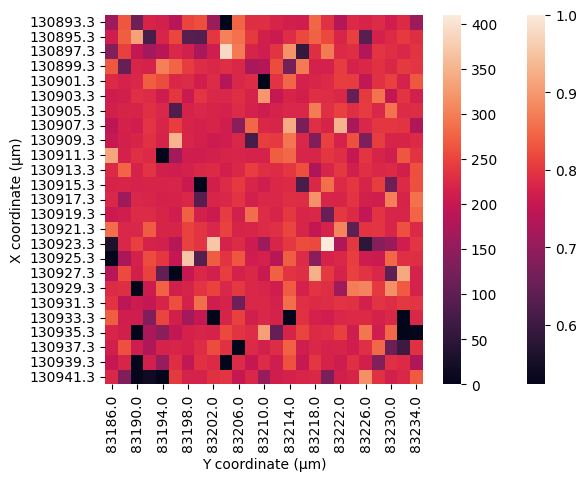

In [7]:
import seaborn as sns
%matplotlib inline

dfMat_E = dfMat[['Elastic modulus (GPa)', 'Hardness (GPa)']] #'X coordinate (µm)', 'Y coordinate (µm)', 
print(dfMat_E)

corr = dfMat_E.select_dtypes('number').corr()

# plot the heatmap
sns.heatmap(corr)

# plot the correlation heatmap
dFMatPivot_E = dfMat.pivot(index="X coordinate (µm)", columns="Y coordinate (µm)", values="Elastic modulus (GPa)")
sns.heatmap(dFMatPivot_E)

<Axes: xlabel='X coordinate (µm)', ylabel='Y coordinate (µm)'>

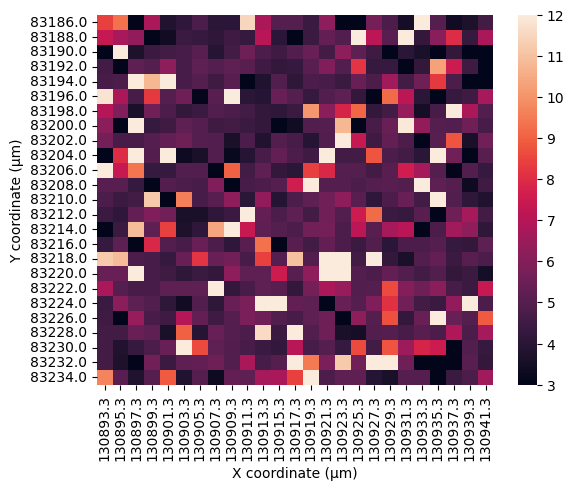

In [8]:
# plot the correlation heatmap
dFMatPivot_H = dfMat.pivot(index="Y coordinate (µm)", columns="X coordinate (µm)", values="Hardness (GPa)")
sns.heatmap(dFMatPivot_H,vmin=3,vmax=12)

## Histogram plots and Gaussian deconvolution

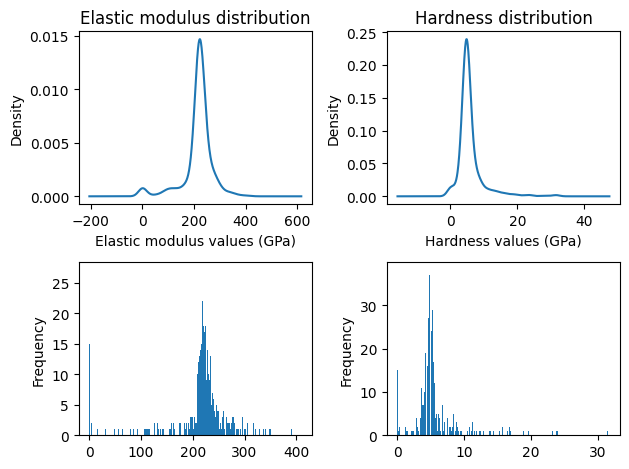

In [9]:
fig = plt.figure()
binsVal=round(df.size/10)

ax1 = fig.add_subplot(221)
ax1 = df['Elastic modulus (GPa)'].plot.kde()
ax11 = fig.add_subplot(223)
ax11 = df['Elastic modulus (GPa)'].plot.hist(bins=binsVal)
ax2 = fig.add_subplot(222)
ax2 = df['Hardness (GPa)'].plot.kde()
ax22 = fig.add_subplot(224)
ax22 = df['Hardness (GPa)'].plot.hist(bins=binsVal)
ax1.title.set_text('Elastic modulus distribution')
ax1.set_xlabel('Elastic modulus values (GPa)')
ax2.title.set_text('Hardness distribution')
ax2.set_xlabel('Hardness values (GPa)')
plt.tight_layout()
plt.show()

In [10]:
# Extract data from the KDE plot for Elastic modulus
kde_data_em = ax1.get_lines()[0].get_data()
x_values_em = kde_data_em[0]
y_values_em = kde_data_em[1]

# Extract data from the KDE plot for Hardness
kde_data_hardness = ax2.get_lines()[0].get_data()
x_values_hardness = kde_data_hardness[0]
y_values_hardness = kde_data_hardness[1]

# Now you can use x_values_em, y_values_em, x_values_hardness, and y_values_hardness as needed

C:\Users\dmercier\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)
C:\Users\dmercier\AppData\Local\Temp\ipykernel_2888\2622225974.py:14: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


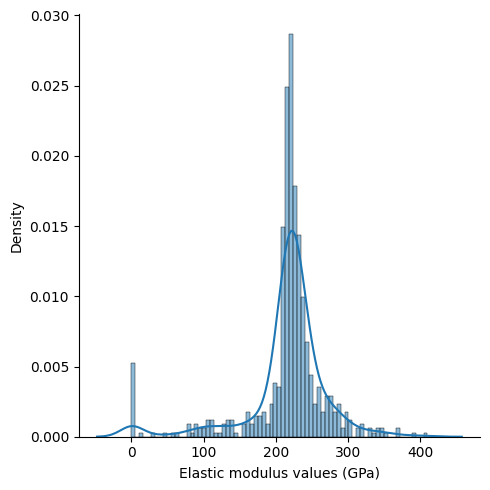

C:\Users\dmercier\AppData\Local\Programs\Python\Python311\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)
C:\Users\dmercier\AppData\Local\Temp\ipykernel_2888\2622225974.py:24: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


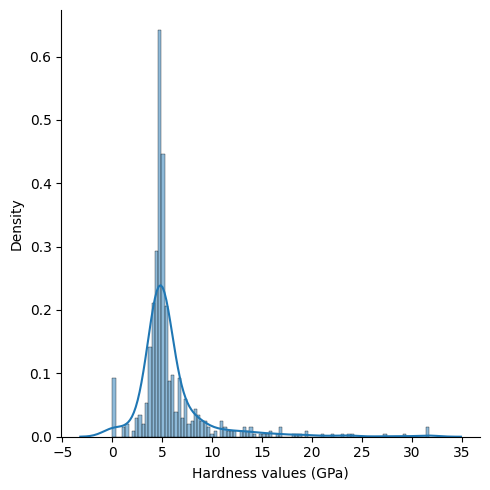

In [11]:
import seaborn as sns
from scipy.stats import norm

data = norm.rvs(5,0.4,size=1000) # you can use a pandas series or a list if you want

# Define subplots
ax1 = fig.add_subplot(221)
ax1 = sns.displot(df['Elastic modulus (GPa)'], kde=True,
    stat="density", kde_kws=dict(cut=3))
ax1.set_titles('Elastic modulus distribution')
ax1.set_xlabels('Elastic modulus values (GPa)')
plt.savefig('PDF_E.png', bbox_inches='tight')
plt.savefig('PDF_E.pdf', bbox_inches='tight')
plt.tight_layout()
plt.show()

ax2 = fig.add_subplot(222)
ax2 = sns.displot(df['Hardness (GPa)'], kde=True,
    stat="density", kde_kws=dict(cut=3))
ax2.set_titles('Hardness distribution')
ax2.set_xlabels('Hardness values (GPa)')
plt.savefig('PDF_H.png', bbox_inches='tight')
plt.savefig('PDF_H.pdf', bbox_inches='tight')
plt.tight_layout()
plt.show()


## K-means clustering analysis

C:\Users\dmercier\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


[[  5.34989293 222.55546039]
 [  0.34782609   9.95652174]
 [ 11.1475     291.49625   ]
 [  4.84181818 134.33272727]]


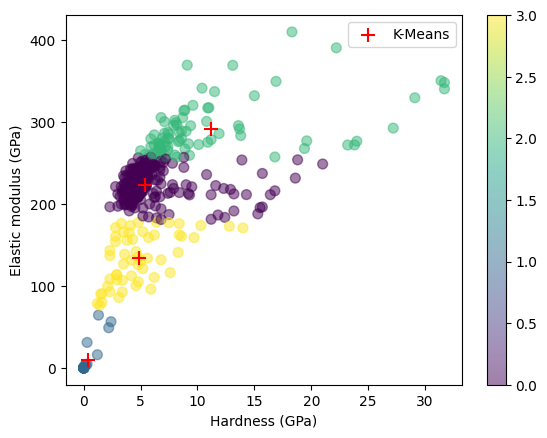

In [12]:
# K-MEANS CLUSTERING
# Importing Modules
from sklearn import datasets
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
numComp = 4
random_stateVal = 42
sizePnt = 50
sizeMean = 100
alphaVal = 0.5
cmapVal = 'viridis'
colorMean = 'red'
markerSym = '+'

dfCluster=df[["Hardness (GPa)", "Elastic modulus (GPa)"]]
kmeans = KMeans(n_clusters=numComp, random_state=random_stateVal).fit(dfCluster)
y_pred = kmeans.predict(dfCluster)
centroids = kmeans.cluster_centers_
print(centroids)

# Plot the data points with color-coded clusters
plt.scatter(df['Hardness (GPa)'], df['Elastic modulus (GPa)'], c=y_pred, s=sizePnt, alpha=alphaVal, cmap=cmapVal) #kmeans.labels_.astype(float)
plt.colorbar()

# Plot the K-means centroids
plt.scatter(centroids[:, 0], centroids[:, 1], c=colorMean, marker=markerSym, s=sizeMean, label='K-Means')

plt.xlabel('Hardness (GPa)')
plt.ylabel('Elastic modulus (GPa)')
plt.savefig('ClusterAnalysis.png', bbox_inches='tight')
plt.savefig('ClusterAnalysis.pdf', bbox_inches='tight')
plt.legend(loc='best')
plt.savefig('K-means.jpg')
plt.show()

## Elbow Method for Finding the Optimal Number of Clusters in K-Means

C:\Users\dmercier\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
C:\Users\dmercier\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
C:\Users\dmercier\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\cluster\_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
C:\Users\dmercier\AppData\Local\Programs\Python\Python311\Lib\site-packages\

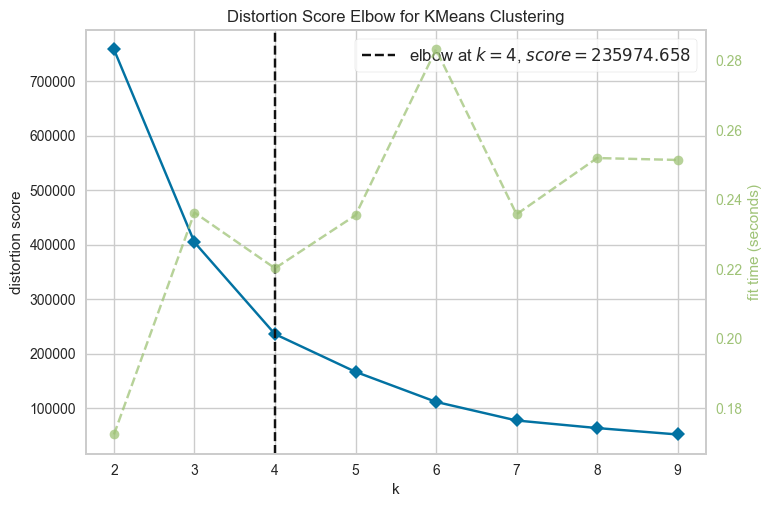

KElbowVisualizer(ax=<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>,
                 estimator=KMeans(n_clusters=9, random_state=5), k=(2, 10))

In [13]:
from sklearn.cluster import KMeans
from yellowbrick.cluster.elbow import kelbow_visualizer

# Extract the columns from the DataFrame
X = dfCluster.values  # Convert the DataFrame to a numpy array

# Use the quick method and immediately show the figure
kelbow_visualizer(KMeans(random_state=5), X, k=(2, 10))

## Gaussian clustering analysis

[[4.74820140e+00 2.23113379e+02]
 [1.24490734e-02 2.48981467e-01]
 [1.38970667e+01 2.37249924e+02]
 [5.83884931e+00 2.10881008e+02]]


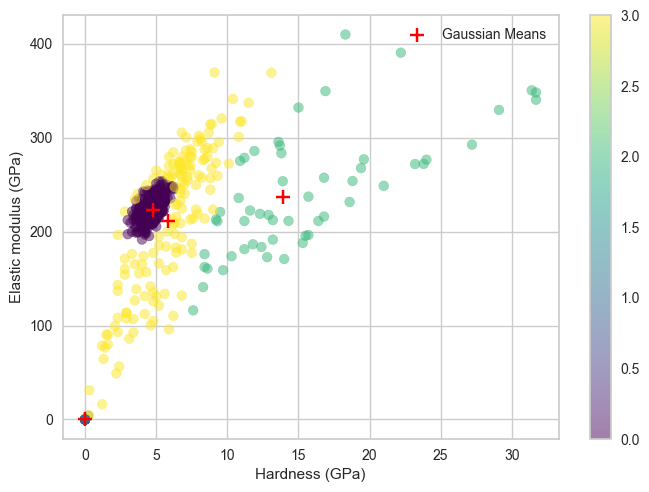

In [14]:
from sklearn.mixture import GaussianMixture
numGauss = 4

# Create and fit a Gaussian Mixture Model
gmm = GaussianMixture(n_components=numGauss, random_state=random_stateVal)
gmm.fit(dfCluster)

# Predict cluster assignments for each data point
y_pred = gmm.predict(dfCluster)

# Get the means and covariances of the Gaussian components
means = gmm.means_
print(means)
covariances = gmm.covariances_

# Plot the data points with color-coded clusters
plt.scatter(dfCluster['Hardness (GPa)'], dfCluster['Elastic modulus (GPa)'], c=y_pred, s=sizePnt, alpha=alphaVal, cmap=cmapVal)
plt.colorbar()

# Plot the Gaussian component means
plt.scatter(means[:, 0], means[:, 1], c=colorMean, marker=markerSym, s=sizeMean, label='Gaussian Means')

plt.xlabel('Hardness (GPa)')
plt.ylabel('Elastic modulus (GPa)')
#plt.title('Gaussian Mixture Model')
plt.legend(loc='best')
plt.savefig('GMM.jpg')
plt.show()

## K-medoid clustering analysis

In [15]:
centroids
means

array([[4.74820140e+00, 2.23113379e+02],
       [1.24490734e-02, 2.48981467e-01],
       [1.38970667e+01, 2.37249924e+02],
       [5.83884931e+00, 2.10881008e+02]])

In [46]:
#Comparison with SEM image
plt.figure(figsize=(8, 6))
sns.kdeplot(data=dfMat('Elastic modulus (GPa)'), x="X position (µm)", y="Y position (µm)", fill=True, thresh=0, levels=20)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Kernel Density Estimate (KDE) Plot')
plt.show()

TypeError: 'DataFrame' object is not callable

<Figure size 800x600 with 0 Axes>

## Import results into the MI database

In [17]:
from datetime import datetime
from GRANTA_MIScriptingToolkit import granta as mpy
import pathlib

mi = mpy.connect('https://nanomecommons.grantami.com/mi_servicelayer',  user_name=usernameVal, password=passwordVal)
db = mi.get_db(db_key="MI_Blank_v2021")
test_table = db.get_table('Indentation statistical data')
folderName = 'Python Demo'

now = datetime.now().strftime("%c")
record_name = 'STK Example :{}'.format(now)
record = test_table.path_from(None, tree_path=['', folderName], end_node=record_name)
record
operatorName = "D. Mercier"

MechPropStr = ['Reduced elastic modulus (mean)', 'Hardness (mean)']

new_file = record.attributes['Other data']
new_pict = record.attributes['Picture']
build_date = record.attributes['Analysis Date']
operator = record.attributes['Operator']
sample_name = record.attributes['Specimen sample name']
E_val = record.attributes[MechPropStr[0]]
H_val = record.attributes[MechPropStr[1]]

new_file

KeyError: 'Specimen sample name'

In [ ]:
#Import files and data into MI

file_object = mpy.File()
filename = 'ClusterAnalysis.pdf'
with open(filename, 'rb') as file_buffer:
    file_object.binary_data = file_buffer.read()
file_object.name = filename
file_object.description = 'This is an example file'
new_file.object = file_object
new_file

picture = pathlib.Path('./ClusterAnalysis.png')
new_pict.load(picture)
new_pict

build_date.value = datetime.now()

operator.value = operatorName
sample_name.value = recordName

E_val.value = centroids[0,0]
H_val.value = centroids[0,1]

centroids

record.set_attributes([build_date, new_file, new_pict, operator, sample_name, E_val, H_val])
record = mi.update([record], include_binary_data_in_refresh=True)[0]

#new_pict = record.attributes['Image']
#from IPython.display import Image
#Image(new_pict.value)
#new_pict.save(path='./check.jpg')

In [ ]:
#min-max for each corresponding meta attribute of each mechanical properties
maxminStr = ['Maximum', 'Minimum']

recE = record.attributes[MechPropStr[0]]
funcMax = recE.meta_attributes[maxminStr[0]]
funcMax.value = max(x_values_em)
funcMin = recE.meta_attributes[maxminStr[1]]
funcMin.value = min(x_values_em)
record.set_attributes([recE, funcMax, funcMin])

recH = record.attributes[MechPropStr[1]]
funcMax = recH.meta_attributes[maxminStr[0]]
funcMax.value = max(x_values_hardness)
funcMin = recH.meta_attributes[maxminStr[1]]
funcMin.value = min(x_values_hardness)
record.set_attributes([recH, funcMax, funcMin])

record = mi.update([record])[0]

In [ ]:
#Add probability distribution into the meta attribute of each mechanical properties
recE = record.attributes[MechPropStr[0]]
funcE = recE.meta_attributes['Probability distribution - Reduced elastic modulus']
recH = record.attributes[MechPropStr[1]]
funcH = recH.meta_attributes['Probability distribution - Hardness']
funcH.column_headers

In [ ]:
for xE, yE in zip(x_values_em, y_values_em):
    funcE.add_point({'Young\'s modulus [GPa]': xE, 'y': yE})
funcE.series_linestyles[1] = 'Markers'
#funcE.series_linestyles
#funcE.value
record.set_attributes([funcE])
mi.update([record])

In [ ]:
for xH, yH in zip(x_values_hardness, y_values_hardness):
    funcH.add_point({'Hardness [GPa]': xH, 'y': yH})
funcH.series_linestyles[1] = 'Markers'
#funcH.series_linestyles
#funcH.value
record.set_attributes([funcH])
mi.update([record])

## Add link to the test record

In [ ]:
# Add link into "Indentation statistical data"
new_linked_recs = record.links['Indentation test data']
new_linked_recs.add(Indrecord)
record.set_links('Indentation test data', new_linked_recs)

record = mi.update_links([record])[0]
print(record.links)

# Add link into "Indentation test data"
new_linked_recs = Indrecord.links['Indentation statistical data']
new_linked_recs.add(record)
Indrecord.set_links('Indentation statistical data', new_linked_recs)

Indrecord = mi.update_links([Indrecord])[0]
print(Indrecord.links)

## Change meta attributes of folders and records (color...)

In [ ]:
folder = test_table.path_from(None, tree_path=['', folderName])
folder.color = mpy.RecordColor.White
record.color = mpy.RecordColor.White
mi.update([folder, record])